# Entrenamiento de CNN ResNet-18 con Transfer Learning

Este notebook será ejecutado varias veces con distintos parámetros.

Para ello se utilizará Papermill, una herramienta para parametrizar y ejecutar Jupyter Notebooks.

Los datos mostrados en este notebook son únicamente datos de prueba.

## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Detener el entrenamiento si val_loss no mejora suficientemente durante la paciencia configurada.
- Evaluar el modelo de la mejor época de validación sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos restaurados de la mejor época de validación (o los finales si se desactiva la parada anticipada).

In [1]:
# Importaciones

import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen_desde_metadata,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CPU


In [4]:
# Parámetros

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
NUM_WORKERS = 8  # Usar 0 para desactivar la carga paralela.
EPOCHS = 2  # Máximo de épocas.
EARLY_STOPPING_PATIENCE = 15  # None desactiva la parada anticipada.
EARLY_STOPPING_MIN_DELTA = 0.001
USE_CLASS_WEIGHTS = False
USE_AMP = True
USE_CHANNELS_LAST = True
LR = 1e-3

UNFREEZE_EPOCH = None
BACKBONE_LR_FACTOR = 0.1

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Datos de entrada y división persistida
DATASET_NAME = "completos"

## División de datos

La pertenencia de cada imagen a `train`, `val` o `test` se lee de la metadata generada por el notebook de división. La relación se realiza mediante `ruta_relativa`; por tanto, el split no se recalcula aunque cambien la semilla o los parámetros del entrenamiento.

In [5]:
# Metadata, transformaciones y dataloaders
# Resolver después de la inyección de parámetros de Papermill.
rutas_dataset = {
    "completos": PATHS.DATA_CUADRADOS_DIVIDIDO,
    "unificado": PATHS.DATA_UNIFICADO_DIVIDIDO,
}
if DATASET_NAME not in rutas_dataset:
    raise ValueError(
        f"Dataset desconocido: {DATASET_NAME!r}. Opciones: {', '.join(rutas_dataset)}"
    )
DATA_DIR = rutas_dataset[DATASET_NAME]
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"No existe el directorio del dataset: {DATA_DIR}")
if not (DATA_DIR / "metadata.csv").is_file():
    raise FileNotFoundError(
        f"No existe la metadata de split: {DATA_DIR / 'metadata.csv'}"
    )
print(f"Dataset seleccionado: {DATASET_NAME}")
print(f"Directorio de datos: {DATA_DIR}")
metadata_split = cargar_metadata(DATA_DIR)

config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)

dataloaders = crear_dataloaders_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    configuracion_transformaciones=config_transformaciones,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print(f"Metadata de split: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print("Clases:", *class_names)
print(
    f"Split persistido -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Dataset seleccionado: completos
Directorio de datos: C:\Users\rafae\Dev\vasijas\data\10.cuadrados_divididos_en_train_val_y_test
Metadata de split: data\10.cuadrados_divididos_en_train_val_y_test\metadata.csv
Clases: clase01 clase02 clase03 clase05 clase06 clase07 clase08 clase09 clase10 clase11
Split persistido -> train: 749, val: 161, test: 161


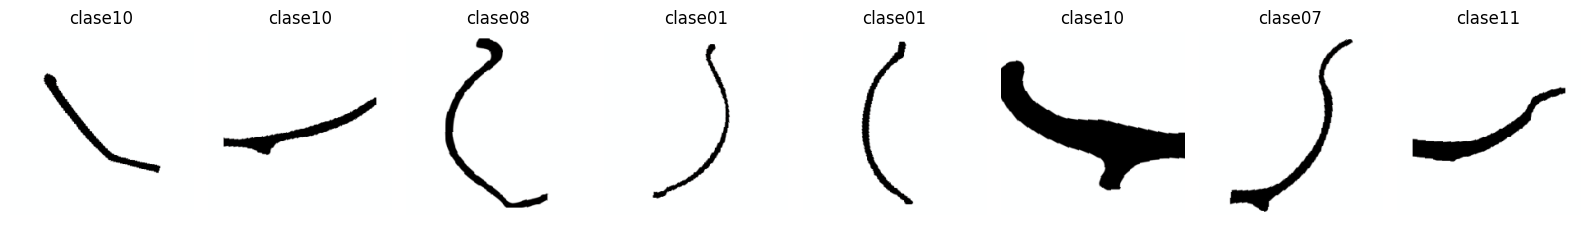

In [6]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(loader=train_loader, nombres_clases=class_names, cantidad=8)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [7]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada(
    usar_pesos_clases=USE_CLASS_WEIGHTS,
    train_loader=train_loader,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [8]:
# Entrenamiento y validación
backbone_lr = LR * BACKBONE_LR_FACTOR

historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    usar_amp=USE_AMP,
    usar_channels_last=USE_CHANNELS_LAST,
    epochs=EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    model_name=MODEL_NAME,
    unfreeze_epoch=UNFREEZE_EPOCH,
    backbone_lr=backbone_lr,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/2
Train Loss: 1.5910 | Train Acc: 0.5314 | Val Loss: 1.5806 | Val Acc: 0.5280
Tiempo de epoch: 0:01:37.960665 

Epoch 2/2
Train Loss: 1.2206 | Train Acc: 0.6262 | Val Loss: 1.2633 | Val Acc: 0.6460
Tiempo de epoch: 0:00:31.932122 

Se restauran los pesos de epoch 2 (val_loss=1.2633).
Tiempo total de entrenamiento: 0:02:09.947467


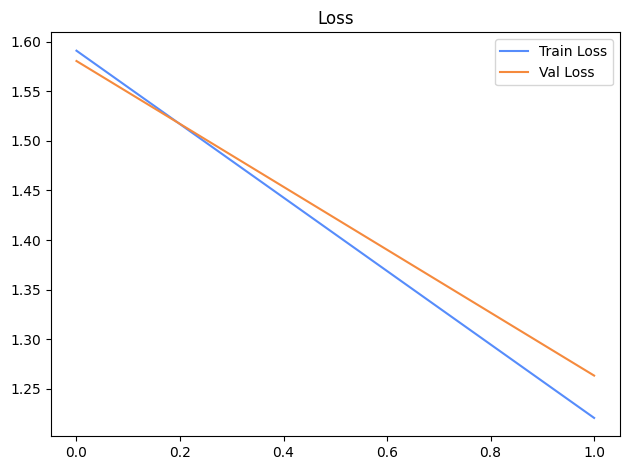

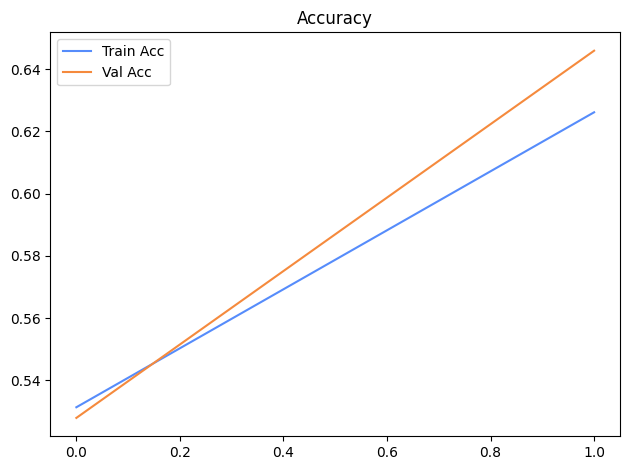

In [9]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.6087
              precision    recall  f1-score   support

     clase01       0.00      0.00      0.00         4
     clase02       0.00      0.00      0.00         7
     clase03       0.00      0.00      0.00        11
     clase05       0.27      0.38      0.32         8
     clase06       0.00      0.00      0.00         8
     clase07       0.00      0.00      0.00         7
     clase08       0.54      0.95      0.69        42
     clase09       0.00      0.00      0.00         3
     clase10       0.72      1.00      0.83        53
     clase11       1.00      0.11      0.20        18

    accuracy                           0.61       161
   macro avg       0.25      0.24      0.20       161
weighted avg       0.50      0.61      0.49       161



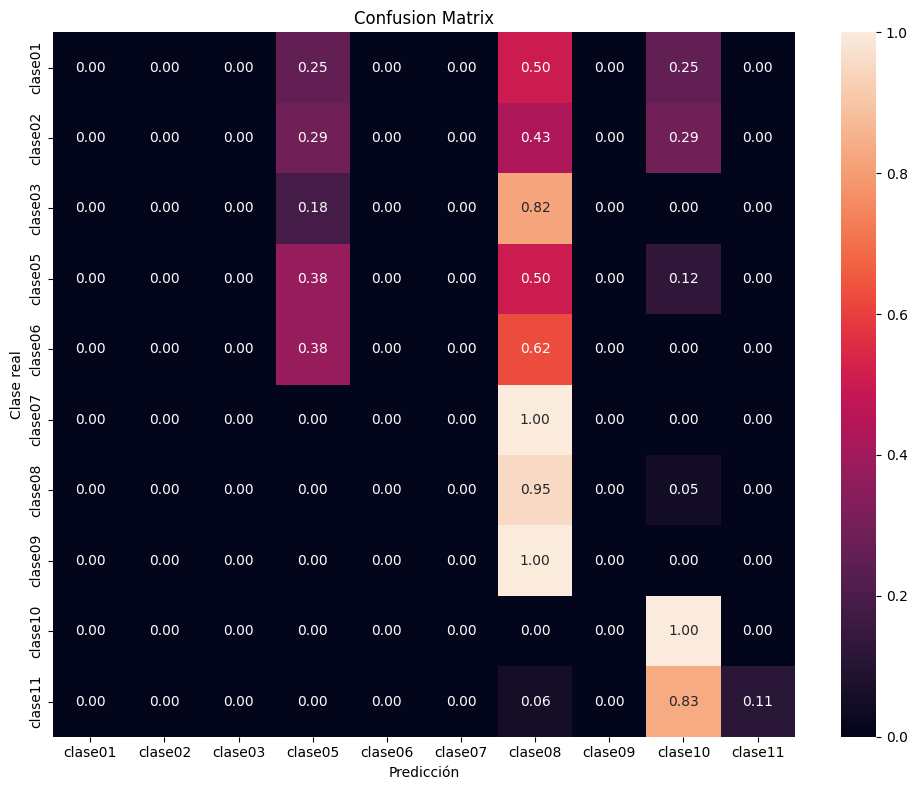

In [10]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
    usar_amp=USE_AMP,
    usar_channels_last=USE_CHANNELS_LAST,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [11]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS
    / f"model_{MODEL_NAME}_{DATASET_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_relativa(ruta_modelo)}")

Modelo guardado en: output\models\model_resnet18_completos_default.pth
